# 04 · Comparar las versiones y transferir el estilo

## Qué vas a aprender

- A **compararte con una línea base barata** antes de dar por bueno un modelo grande.
- A leer una **tabla comparativa** con varias métricas a la vez (error en los ajustes, parecido con el resultado ideal, tiempo y tamaño).
- A **transferir un estilo de color** de una foto a otra con la versión ganadora y a revisar el resultado a ojo.
- A **registrar en MLflow** un modelo como «modelo de producción» (y el adaptador LoRA como candidato descartado).
- **Cuándo sí** tendría sentido usar un LLM.

## Dónde estamos

Ya tenemos **A** (el LLM de visión sin entrenar, notebook 02) y **B** (el mismo con LoRA, notebook 03; error peor que contestar la media). Añadimos las comparaciones honestas:

- **C · Línea base pequeña.** Una red de visión clásica y diminuta (**MobileNetV3-small**, preentrenada en ImageNet) **congelada**, que convierte la foto en 576 números, y encima una **regresión lineal** (Ridge) que predice los cinco ajustes.
- **C_color · Estadísticas de color.** La misma regresión, pero alimentada con **27 estadísticas de color** calculadas a mano. Sin red neuronal.
- **D · Reinhard (2001).** Método clásico que no predice ajustes: iguala la media y la desviación de cada canal de color (en espacio **Lab**) de la foto de contenido a las de la referencia. Sin entrenamiento.
- **«media»** y **«neutro»**: contestar siempre la media de train, o «no se tocó nada».
- **2c**: el último intento del LLM del notebook 03 (estadísticas escritas en el prompt + LoRA). Sus cifras se **citan** del estudio técnico; no se reentrena aquí.

## Dos etapas (parámetro `ETAPA`)

Para poder repartirlo en dos *jobs* de CI:

- `c_d`: solo calcula C y D y guarda `resultados/pred_C.jsonl`, `metricas_C.json` y `metricas_D.json`. **No toca MLflow.**
- `completo` (por defecto): lee lo de A, B, C y D, hace la tabla (`resultados/tabla_comparativa.csv` y `.json`), el panel (`resultados/panel_transferencia.png`) y registra en MLflow. Si falta C, lo calcula.

> **Tiempo:** unos 40 s en CPU (medido el 20/11/2026), porque lee los resultados de A y B ya calculados.

In [1]:
import os
N_EJEMPLOS = int(os.environ.get('ESTILO_N_EJEMPLOS', '60'))
EPOCAS = int(os.environ.get('ESTILO_EPOCAS', '2'))
RESOLUCION = int(os.environ.get('ESTILO_RESOLUCION', '224'))
MODELO = os.environ.get('ESTILO_MODELO', 'HuggingFaceTB/SmolVLM-256M-Instruct')
CARPETA_TRABAJO = os.environ.get('ESTILO_TRABAJO', '_trabajo')
ETAPA = os.environ.get('ESTILO_ETAPA', 'completo')  # «c_d» o «completo»
N_PANEL = 4  # parejas que se dibujan en el panel

In [2]:
import csv, json
import numpy as np
import matplotlib.pyplot as plt
import estilo as ce

assert ETAPA in ('c_d', 'completo'), ETAPA
plt.rcParams['figure.dpi'] = 55
trabajo = ce.carpeta_trabajo(CARPETA_TRABAJO)
resultados = trabajo / 'resultados'; resultados.mkdir(exist_ok=True)
hilos = ce.limitar_hilos()
import torch, torchvision, sklearn
print('torch', torch.__version__, '| torchvision', torchvision.__version__, '| scikit-learn', sklearn.__version__, '| hilos:', hilos, '| ETAPA:', ETAPA)
train, test = ce.leer_parejas(trabajo, 'train'), ce.leer_parejas(trabajo, 'test')

def leer_pred(v):
    filas = (resultados / f'pred_{v}.jsonl').read_text(encoding='utf-8').splitlines()
    return {d['id']: d for d in map(json.loads, filter(None, filas))}

def guardar_pred(v, d):
    (resultados / f'pred_{v}.jsonl').write_text('\n'.join(json.dumps(dict(x, id=k)) for k, x in d.items()), encoding='utf-8')

pred = {}
print(len(train), 'de entrenamiento,', len(test), 'de test')

torch 2.15.0+cpu | torchvision 0.29.2+cpu | scikit-learn 1.9.1 | hilos: 12 | ETAPA: completo
210 de entrenamiento, 60 de test


## 1. Versiones C y C_color: aprendizaje por transferencia, sin LLM

**C** es el «aprendizaje por transferencia» de la S3 en su versión más simple: no se entrena la red, solo la regresión de encima (segundos). Como referencias aún más tontas añadimos «neutro» (contestar siempre «no se tocó nada») y «media» (contestar siempre la media de train).

**C_color** responde a la pregunta incómoda: ¿hace falta un modelo grande para esto? Le damos a la misma regresión **27 estadísticas de color**:

- en Lab: media, desviación y percentiles 5, 50 y 95 de cada canal (15 números);
- en RGB: media, desviación y percentiles 1 y 99 de cada canal (12 números).

Son los mismos números que escribimos como texto en el prompt de la variante 2c del notebook 03.

In [3]:
from sklearn.linear_model import RidgeCV
Y = np.array([[f['ajustes'][k] for k in ce.NOMBRES] for f in train])

if ETAPA == 'c_d' or not (resultados / 'pred_C.jsonl').exists():
    from torchvision.models import mobilenet_v3_small, MobileNet_V3_Small_Weights

    pesos = MobileNet_V3_Small_Weights.IMAGENET1K_V1
    red = mobilenet_v3_small(weights=pesos).eval()
    transformar = pesos.transforms()

    def rasgos(filas):
        with torch.no_grad():
            x = torch.stack([transformar(ce.abrir(trabajo, f['editada'])) for f in filas])
            return red.avgpool(red.features(x)).flatten(1).numpy()  # 576 números por foto

    with ce.Cronometro() as c_train:
        regresion = RidgeCV(alphas=np.logspace(-2, 3, 12)).fit(rasgos(train), Y)
    with ce.Cronometro() as c_inf:
        salida = regresion.predict(rasgos(test))
    guardar_pred('C', {f['id']: {'pred': ce.recortar_a_rango(dict(zip(ce.NOMBRES, fila)))} for f, fila in zip(test, salida)})
    metC = ce.error_por_ajuste([ce.recortar_a_rango(dict(zip(ce.NOMBRES, fila))) for fila in salida], [f['ajustes'] for f in test])
    metC.update(s_entrenamiento=c_train.s, s_inferencia_por_foto=c_inf.s / len(test), alfa=float(regresion.alpha_),
                mb_modelo=round((sum(p.numel() for p in red.parameters()) + regresion.coef_.size) * 4 / 2**20, 2))
    (resultados / 'metricas_C.json').write_text(json.dumps(metC, indent=1), encoding='utf-8')
    print(f"C: entrenamiento (rasgos + regresión) {c_train.s:.1f} s; inferencia {metC['s_inferencia_por_foto'] * 1000:.0f} ms por foto; "
          f"alfa elegido {regresion.alpha_:.3g}; tamaño ≈ {metC['mb_modelo']} MB en float32")
else:
    print('C ya calculado en la etapa c_d: se lee de resultados/')
pred['C'] = leer_pred('C')

# C_color: 27 estadísticas de color + la misma regresión (segundos, sin red neuronal)
with ce.Cronometro() as c_color:
    reg_color = ce.ajustar_ridge_color([ce.abrir(trabajo, f['editada']) for f in train], [f['ajustes'] for f in train])
    salida_color = ce.predecir_ridge_color(reg_color, [ce.abrir(trabajo, f['editada']) for f in test])
pred['C_color'] = {f['id']: {'pred': p} for f, p in zip(test, salida_color)}
print(f'C_color: entrenamiento + inferencia {c_color.s:.1f} s en total ({len(salida_color)} fotos de test, {reg_color.coef_.shape[1]} estadísticas)')

media = ce.ajustes_medios(train)
pred['media'] = {f['id']: {'pred': media} for f in test}
pred['neutro'] = {f['id']: {'pred': dict(ce.NEUTRO)} for f in test}

C ya calculado en la etapa c_d: se lee de resultados/


C_color: entrenamiento + inferencia 5.9 s en total (60 fotos de test, 27 estadísticas)


## 2. Transferir el estilo de verdad: cómo se mide

Para cada foto editada de test (la **referencia**) cogemos otra foto original de test (el **contenido**). Como sabemos qué ajustes tenía la referencia, sabemos también cómo **debería** quedar el contenido: el **objetivo**. Cada versión hace su trabajo:

- **A, B, C y C_color**: miran la referencia, escriben los cinco ajustes y los **aplicamos** al contenido.
- **D (Reinhard)**: no escribe ajustes; modifica el contenido directamente con las estadísticas de la referencia.

Tres métricas de imagen:

- **ΔE medio respecto al objetivo** (CIEDE2000, en Lab): diferencia de color píxel a píxel con el resultado ideal. Hacia 1 apenas se nota; por encima de 10 se ve claramente distinto. **Más bajo es mejor.**
- **Distancia de histogramas con la referencia** (0 = misma distribución de colores). Mide si el resultado «tiene los colores» de la referencia. Ojo: un método que copia la distribución de la referencia (como D) gana aquí aunque se aleje del objetivo.
- **SSIM con el contenido** (0 a 1, en grises): cuánto se conserva la estructura de la foto. Cambiar el color también lo baja un poco; por eso damos también el SSIM del propio objetivo como techo razonable.

In [4]:
def transferir(version, ref, cont):
    """Foto de referencia -> (modelo) -> JSON -> aplicar el JSON a la foto de contenido."""
    img_ref, img_cont = ce.abrir(trabajo, ref['editada']), ce.abrir(trabajo, cont['original'])
    if version == 'D':
        return ce.reinhard(img_ref, img_cont)
    if version == 'objetivo':
        return ce.aplicar_ajustes(img_cont, ref['ajustes'])
    if version == 'sin cambio':
        return img_cont
    return ce.aplicar_ajustes(img_cont, pred[version][ref['id']]['pred'])

def medir(version):
    m = {'delta_e_objetivo': [], 'dist_hist_referencia': [], 'ssim_contenido': [], 'ms_aplicar': []}
    for ref, cont in ce.parejas_transferencia(test):
        img_ref, img_cont = ce.abrir(trabajo, ref['editada']), ce.abrir(trabajo, cont['original'])
        with ce.Cronometro() as c:
            salida = transferir(version, ref, cont)
        m['ms_aplicar'].append(c.s * 1000)
        m['delta_e_objetivo'].append(ce.delta_e(salida, transferir('objetivo', ref, cont)))
        m['dist_hist_referencia'].append(ce.distancia_histogramas(salida, img_ref))
        m['ssim_contenido'].append(ce.ssim_contenido(salida, img_cont))
    return {k: float(np.mean(x)) for k, x in m.items()}

if ETAPA == 'c_d':
    metC = json.loads((resultados / 'metricas_C.json').read_text(encoding='utf-8')); metC.update(medir('C'))
    metD = medir('D'); metD.update(s_entrenamiento=0.0, s_inferencia_por_foto=metD['ms_aplicar'] / 1000, mb_modelo=0.0)
    for v, m in (('C', metC), ('D', metD)):
        (resultados / f'metricas_{v}.json').write_text(json.dumps(m, indent=1), encoding='utf-8')
        print(v, {k: round(x, 3) for k, x in m.items() if not k.startswith('mae')})
    print('Etapa c_d terminada: métricas de C y D guardadas en resultados/')
else:
    print('ETAPA = completo: las métricas de imagen se miden en la tabla de abajo')

ETAPA = completo: las métricas de imagen se miden en la tabla de abajo


## 3. Tabla comparativa (etapa `completo`)

Primero, **¿quién lee mejor los ajustes?** (MAE normalizado por ajuste; 0 = perfecto). **Un modelo que no mejora a «media» no ha aprendido nada de la foto.** Después, la tabla completa con las métricas de imagen, los tiempos y los tamaños.

La fila **2c** es la excepción: sus cifras no se miden aquí, se **citan** del estudio técnico (ronda 2, 20/11/2026), porque no guardamos sus predicciones. Por eso no tiene métricas de imagen (aparecen con un guion).

In [5]:
if ETAPA == 'completo':
    pred['A'], pred['B'] = leer_pred('A'), leer_pred('B')
    met = {v: json.loads((resultados / f'metricas_{v}.json').read_text(encoding='utf-8')) for v in 'ABC'}
    reales = [f['ajustes'] for f in test]
    errores = {v: ce.error_por_ajuste([pred[v][f['id']]['pred'] for f in test], reales) for v in ('neutro', 'media', 'A', 'B', 'C', 'C_color')}

    # Cifras de la variante 2c, CITADAS del estudio técnico (ronda 2, 20/11/2026): no se reentrena aquí.
    CITA_2C = {'maen': {'exposicion': 0.263, 'temperatura': 0.219, 'tinte': 0.240, 'contraste': 0.153, 'saturacion': 0.345},
               'mae_normalizado_medio': 0.244, 'formato_correcto': 1.0, 's_inferencia_por_foto': 3.123, 's_entrenamiento': 494.434}
    errores['2c (cita)'] = {'maen_' + k: x for k, x in CITA_2C['maen'].items()} | {'mae_normalizado_medio': CITA_2C['mae_normalizado_medio']}

    print(f"{'versión':10s}" + ''.join(f'{k:>12s}' for k in ce.NOMBRES) + f"{'MEDIA':>9s}")
    for v, e in errores.items():
        print(f'{v:10s}' + ''.join(f"{e['maen_' + k]:12.3f}" for k in ce.NOMBRES) + f"{e['mae_normalizado_medio']:9.3f}")

versión     exposicion temperatura       tinte   contraste  saturacion    MEDIA
neutro           0.262       0.250       0.249       0.242       0.290    0.259
media            0.262       0.251       0.253       0.240       0.292    0.259
A                0.488       0.492       0.432       0.372       0.380    0.433
B                0.299       0.342       0.285       0.317       0.308    0.310
C                0.245       0.208       0.242       0.222       0.228    0.229
C_color          0.119       0.158       0.147       0.126       0.208    0.151
2c (cita)        0.263       0.219       0.240       0.153       0.345    0.244


In [6]:
if ETAPA == 'completo':
    filas = []
    for v in ['sin cambio', 'objetivo', 'media', 'A', 'B', '2c', 'C', 'C_color', 'D']:
        if v == '2c':   # sin predicciones guardadas: solo las cifras citadas
            filas.append({'version': '2c', **{k: x for k, x in CITA_2C.items() if k != 'maen'}})
            continue
        fila = {'version': v, **medir(v)}
        if v in errores:
            fila['mae_normalizado_medio'] = errores[v]['mae_normalizado_medio']
        if v in ('A', 'B'):
            fila.update(formato_correcto=met[v]['formato_correcto'], s_inferencia_por_foto=met[v]['segundos_por_foto'], mb_modelo=met['B']['base_mb'])
        if v == 'A':
            fila['s_entrenamiento'] = 0.0
        if v == 'B':
            fila.update(s_entrenamiento=met['B']['segundos_entrenamiento'] + met['B']['segundos_preparacion'], mb_adaptador=met['B']['adaptador_mb'])
        if v == 'C':
            fila.update({k: met['C'][k] for k in ('s_entrenamiento', 's_inferencia_por_foto', 'mb_modelo')})
        if v == 'C_color':
            fila.update(s_entrenamiento=c_color.s, mb_modelo=round(reg_color.coef_.size * 4 / 2**20, 4))
        if v == 'D':
            fila.update(s_entrenamiento=0.0, s_inferencia_por_foto=fila['ms_aplicar'] / 1000, mb_modelo=0.0)
        filas.append(fila)

    columnas = ['version', 'mae_normalizado_medio', 'formato_correcto', 'delta_e_objetivo', 'dist_hist_referencia', 'ssim_contenido',
                's_inferencia_por_foto', 's_entrenamiento', 'mb_modelo', 'mb_adaptador']
    with open(resultados / 'tabla_comparativa.csv', 'w', newline='', encoding='utf-8') as fh:
        w = csv.writer(fh); w.writerow(columnas)
        for f in filas:
            w.writerow([f['version']] + [('' if c not in f else f'{f[c]:.3f}') for c in columnas[1:]])
    (resultados / 'tabla_comparativa.json').write_text(json.dumps(filas, indent=1, ensure_ascii=False), encoding='utf-8')

    cabecera = ['versión', 'MAE norm.', 'formato', 'ΔE objetivo', 'dist. hist.', 'SSIM cont.', 's/foto', 's entren.', 'MB modelo', 'MB adapt.']
    print(f'{cabecera[0]:11s}' + ''.join(f'{c:>12s}' for c in cabecera[1:]))
    for f in filas:
        print(f"{f['version']:11s}" + ''.join(f"{('-' if c not in f else format(f[c], '.3f')):>12s}" for c in columnas[1:]))
    print('(C_color: el tiempo de entrenamiento incluye también la inferencia de test; 2c: cifras citadas del estudio técnico)')
    por_version = {f['version']: f for f in filas}
else:
    print('ETAPA = c_d: la tabla se hace en la etapa «completo»')

versión       MAE norm.     formato ΔE objetivo dist. hist.  SSIM cont.      s/foto   s entren.   MB modelo   MB adapt.
sin cambio            -           -      14.413       0.534       1.000           -           -           -           -
objetivo              -           -       0.000       0.391       0.820           -           -           -           -
media             0.259           -      14.715       0.535       0.988           -           -           -           -
A                 0.433       0.550      22.206       0.594       0.815       5.050       0.000     493.900           -
B                 0.310       1.000      15.986       0.552       0.937       4.910    1123.348     493.900       7.060
2c                0.244       1.000           -           -           -       3.123     494.434           -           -
C                 0.229           -      13.212       0.508       0.948       0.031       7.068       9.710           -
C_color           0.151           -     

## 4. Panel visual

Cada fila es una pareja: la **referencia** (de donde copiamos el estilo), el **contenido** (la foto a la que se lo aplicamos), el **objetivo** (cómo debería quedar) y las versiones. Debajo de cada salida, su ΔE con el objetivo (más bajo = mejor). La versión **ganadora** (menor ΔE medio) lleva la etiqueta «ganadora».

El panel se guarda en `resultados/panel_transferencia.png`.

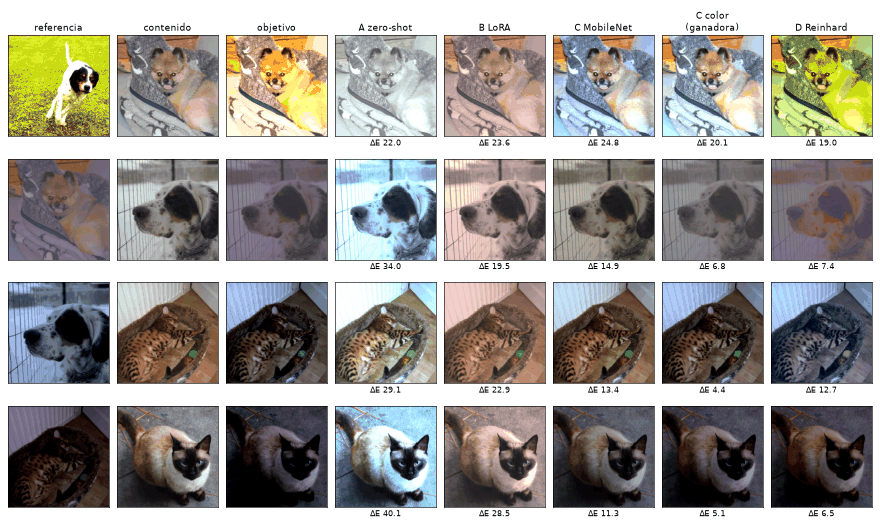

Versión ganadora (menor ΔE medio con el objetivo): C_color


In [7]:
if ETAPA == 'completo':
    from IPython.display import Image as MostrarImagen, display
    cols = ['referencia', 'contenido', 'objetivo', 'A', 'B', 'C', 'C_color', 'D']
    titulos = {'A': 'A zero-shot', 'B': 'B LoRA', 'C': 'C MobileNet', 'C_color': 'C color', 'D': 'D Reinhard'}
    ganadora = min(titulos, key=lambda v: por_version[v]['delta_e_objetivo'])
    titulos[ganadora] += '\n(ganadora)'
    parejas = ce.parejas_transferencia(test)[:N_PANEL]
    fig, ejes = plt.subplots(len(parejas), len(cols), figsize=(16, 2.4 * len(parejas)), squeeze=False)
    for fila, (ref, cont) in enumerate(parejas):
        objetivo = transferir('objetivo', ref, cont)
        for col, v in enumerate(cols):
            img = ce.abrir(trabajo, ref['editada']) if v == 'referencia' else ce.abrir(trabajo, cont['original']) if v == 'contenido' else transferir(v, ref, cont)
            eje = ejes[fila, col]; eje.imshow(img); eje.set_xticks([]); eje.set_yticks([])
            if fila == 0:
                eje.set_title(titulos.get(v, v), fontsize=12)
            if v in titulos:
                eje.set_xlabel(f'ΔE {ce.delta_e(img, objetivo):.1f}', fontsize=11)
    plt.tight_layout()
    ce.guardar_figura(resultados / 'panel_transferencia.png')
    plt.close(fig)
    display(MostrarImagen(filename=str(resultados / 'panel_transferencia.png')))
    print('Versión ganadora (menor ΔE medio con el objetivo):', ganadora)

**Qué debes ver** en el panel (ejecución del 20/11/2026; el panel se revisó a ojo):

- **A y B** dejan la foto con un tono casi igual en todas las filas, sea cual sea la referencia: A la aclara y la azulea, B la tiñe de rosa. No siguen a la referencia.
- **C_color** se parece al objetivo en las filas 2, 3 y 4 (ΔE 6,8, 4,4 y 5,1). En la fila 1 la referencia es muy saturada y amarilla y **todas** las versiones quedan en un ΔE de 19 o más (C_color, 20,1): un resultado malo también se enseña.
- **D** copia los colores de la referencia entera: en la fila 1 tiñe de verde amarillento la foto del perrito y en la fila 3 deja al gato casi gris azulado, como la referencia. Su ΔE es parecido al de C_color en las filas 2 y 4 (7,4 y 6,5) y peor en la 3 (12,7 frente a 4,4).

## 5. La aplicación final y el registro en MLflow

El flujo de la aplicación: foto de referencia → modelo → **JSON de ajustes** → aplicar a otra foto. El JSON es lo interesante: es **legible**, se puede **corregir a mano** y se puede **aplicar a mil fotos** sin volver a llamar al modelo.

Después registramos en la misma base de MLflow donde el 03 dejó el run de B:

- un run por versión (A, C, C_color, D), uno con las cifras citadas de 2c (etiquetado como cita) y uno `comparativa` con la tabla y el panel;
- **C_color** como modelo del *registry* con el alias **`produccion`**: es la versión ganadora;
- el **adaptador LoRA** de B como modelo registrado con el alias **`descartado`** y una etiqueta con el motivo.

In [8]:
if ETAPA == 'completo':
    ref, cont = ce.parejas_transferencia(test)[0]
    print('Lo que escribió B para la referencia:', pred['B'][ref['id']]['respuesta'])
    print('Ajustes reales de la referencia:     ', ce.a_json(ref['ajustes']))
    print('Lo que predice C_color:              ', ce.a_json(pred['C_color'][ref['id']]['pred']))

Lo que escribió B para la referencia: {"exposicion": 0.22, "temperatura": 0.62, "tinte": 0.62, "contraste": 0.82, "saturacion": 0.68}
Ajustes reales de la referencia:      {"exposicion": 0.45, "temperatura": 0.5, "tinte": 0.03, "contraste": 1.35, "saturacion": 1.69}
Lo que predice C_color:               {"exposicion": 0.31, "temperatura": -0.26, "tinte": -0.11, "contraste": 1.17, "saturacion": 1.27}


In [9]:
if ETAPA == 'completo':
    import mlflow.sklearn
    from mlflow.models import infer_signature
    mlflow = ce.mlflow_local(trabajo)
    creados = []
    for v, nombre in (('A', 'A_zero_shot'), ('C', 'C_mobilenet_ridge'), ('C_color', 'C_color_ridge'), ('D', 'D_reinhard')):
        with mlflow.start_run(run_name=nombre) as run_v:
            mlflow.log_params({'version': v, 'n_test': len(test), 'hilos': hilos, 'modelo': MODELO if v == 'A' else '-'})
            mlflow.log_metrics({k: x for k, x in por_version[v].items() if isinstance(x, float)})
            if v == 'C_color':   # el modelo ganador, listo para producción
                X_test = np.array([ce.estadisticas_color(ce.abrir(trabajo, f['editada'])) for f in test[:5]])
                mlflow.sklearn.log_model(reg_color, name='modelo', signature=infer_signature(X_test, reg_color.predict(X_test)),
                                         input_example=X_test, registered_model_name='estilo-color-ridge')
                id_color, exp_id = run_v.info.run_id, run_v.info.experiment_id
        creados.append(nombre)
    with mlflow.start_run(run_name='2c_estadisticas_lora'):   # CITA del estudio técnico, no medido aquí
        mlflow.set_tags({'origen': 'cita del estudio técnico (ronda 2, 20/11/2026)', 'version': '2c'})
        mlflow.log_metrics({k: x for k, x in por_version['2c'].items() if isinstance(x, float)})
    creados.append('2c_estadisticas_lora')
    with mlflow.start_run(run_name='comparativa'):
        mlflow.log_artifact(str(resultados / 'tabla_comparativa.csv'))
        mlflow.log_artifact(str(resultados / 'panel_transferencia.png'))
    creados.append('comparativa')
    print('Runs creados en esta ejecución:', creados)

2026/11/21 00:15:14 WARNING mlflow.utils.requirements_utils: Found torch version (2.15.0+cpu) contains a local version label (+cpu). MLflow logged a pip requirement for this package as 'torch==2.15.0' without the local version label to make it installable from PyPI. To specify pip requirements containing local version labels, please use `conda_env` or `pip_requirements`.


Successfully registered model 'estilo-color-ridge'.
Created version '1' of model 'estilo-color-ridge'.


Runs creados en esta ejecución: ['A_zero_shot', 'C_mobilenet_ridge', 'C_color_ridge', 'D_reinhard', '2c_estadisticas_lora', 'comparativa']


In [10]:
if ETAPA == 'completo':
    cliente = mlflow.MlflowClient()
    # 1) El ganador: C_color como «modelo de producción»
    version_color = max(cliente.search_model_versions("name='estilo-color-ridge'"), key=lambda mv: int(mv.version)).version
    cliente.set_registered_model_alias('estilo-color-ridge', 'produccion', version_color)
    cliente.set_model_version_tag('estilo-color-ridge', version_color, 'mae_normalizado_medio', f"{por_version['C_color']['mae_normalizado_medio']:.3f}")
    print(f"estilo-color-ridge v{version_color}: alias «produccion» (MAE normalizado {por_version['C_color']['mae_normalizado_medio']:.3f})")

    # 2) El adaptador LoRA de B (lo dejó el notebook 03), como candidato descartado.
    #    El adaptador no es un «modelo MLflow», así que se registra con la API de bajo nivel, apuntando a su carpeta en el run de B.
    runs_b = mlflow.search_runs(experiment_ids=[exp_id], filter_string="attributes.run_name = 'B_lora'",
                                order_by=['attributes.start_time DESC'], max_results=1, output_format='list')
    if runs_b:
        id_b = runs_b[0].info.run_id
        if not cliente.search_registered_models("name='estilo-lora-adaptador'"):
            cliente.create_registered_model('estilo-lora-adaptador', description='Adaptador LoRA de SmolVLM-256M (versión B)')
        mv = cliente.create_model_version('estilo-lora-adaptador', source=f'runs:/{id_b}/adaptador', run_id=id_b)
        cliente.set_registered_model_alias('estilo-lora-adaptador', 'descartado', mv.version)
        cliente.set_model_version_tag('estilo-lora-adaptador', mv.version, 'motivo',
                                      f"MAE normalizado {por_version['B']['mae_normalizado_medio']:.3f}, peor que contestar la media ({por_version['media']['mae_normalizado_medio']:.3f})")
        print(f'estilo-lora-adaptador v{mv.version}: alias «descartado»')
    else:
        print('No hay run B_lora en esta base de MLflow: ejecuta antes el notebook 03 (el adaptador no se registra).')

estilo-color-ridge v1: alias «produccion» (MAE normalizado 0.151)


estilo-lora-adaptador v1: alias «descartado»


**Qué debes ver** en la interfaz de MLflow (`mlflow ui --backend-store-uri sqlite:///<carpeta de trabajo>/mlflow.db`):

- En **Experiments**: los runs `A_zero_shot`, `B_lora`, `C_mobilenet_ridge`, `C_color_ridge`, `D_reinhard`, `2c_estadisticas_lora` y `comparativa`.
- En **Models**: `estilo-color-ridge` con el alias `produccion` y `estilo-lora-adaptador` con el alias `descartado`.

Un modelo en el *registry* con un alias es lo que una aplicación cargaría con `models:/estilo-color-ridge@produccion`: así, cambiar de modelo es mover el alias, no tocar la aplicación.

**Si falla:** `database is locked` es que otra ventana de MLflow tiene la base abierta; ciérrala. Si dice que no encuentra `B_lora`, el notebook 03 no se ha ejecutado sobre esta carpeta de trabajo.

## 6. Conclusiones

(Cifras de la ejecución de referencia: 300 fotos, 210 train / 30 val / 60 test, 3 épocas para B.)

1. **A (zero-shot) no sirve.** Sin ayuda, el modelo describe la foto. Si le empezamos la respuesta escribe un JSON, pero **copia los extremos de los rangos del prompt** (0,7, −1, 0,2…): error 0,433, peor que contestar «no se tocó nada».
2. **B (LoRA) aprende el formato, no la tarea.** El 100 % de las respuestas son JSON válidos, pero los números **casi no cambian de una foto a otra**: error 0,310, **peor que «media»** (0,259).
3. **2c (estadísticas en el prompt + LoRA)** es el mejor LLM (0,244), pero por muy poco sobre la media y lejos de la regresión que recibe esos mismos números.
4. **C (MobileNet + regresión)** apenas mejora a la media (0,229). Una red entrenada para reconocer *qué* hay en la foto guarda poca información sobre *cómo* está coloreada; es una explicación nuestra, no algo medido aquí.
5. **C_color (27 estadísticas + regresión) es la ganadora con diferencia**: el menor error en los ajustes (0,151) y el menor ΔE con el objetivo (7,5 frente a 14,4 de no hacer nada), en segundos y sin red neuronal.
6. **D (Reinhard)** copia la distribución de color de la referencia (gana en distancia de histogramas), pero arrastra también los colores del contenido de la referencia (por ejemplo, el césped verde) y **no se acerca más al objetivo que no hacer nada** (ΔE 14,4).

### La lección: antes de afinar un LLM, mide una línea base barata

- Una pérdida que baja y un formato perfecto **no** prueban que el modelo funcione. La prueba es compararse con «contestar siempre la media» y con una regresión de segundos.
- La línea base ganadora cabe en **0,001 MB**, entrena en unos segundos y se explica en una línea. B necesita 493,9 MB de modelo base + 7,06 MB de adaptador y unos 19 minutos de preparación y entrenamiento (1 123 s).
- Lo que sí aporta la idea del LLM es una salida **en texto (JSON)** que se lee, se corrige y se aplica a mil fotos. Pero eso también lo da C_color.

### ¿Y cuándo SÍ tendría sentido un LLM?

Estos son criterios de sentido común, **no medidos en este extra**:

- Cuando la **entrada es lenguaje libre** («hazla más cálida, como un atardecer») y hay que entenderla: una regresión sobre estadísticas no lee frases.
- Cuando la tarea es de **lenguaje o de conocimiento general** y el modelo ya la hace aceptablemente sin entrenar. Aquí no era el caso: A no la hacía.
- Cuando la **línea base barata ya se ha medido** y se queda corta, y se dispone de más datos y de GPU. Con 210 fotos, 3 épocas y CPU no se vio mejora; más datos, más épocas u otros modelos **no se probaron**.
- Y aun así, mide: en el estudio técnico, un LLM entrenado para **explicar** el JSON en español escribía frases impecables y acertaba el sentido de los ajustes en el 60,5 % de los casos (el azar entre dos sentidos es 50 %), con alucinaciones en el 58,3 % de las frases; las reglas de plantilla daban el 100 %. **Fluido no es correcto.**

## Qué te llevas

- Una **tabla comparativa** con una línea base barata es la primera pantalla de cualquier proyecto con un modelo grande.
- La mejor solución aquí fue la **más simple**: 27 estadísticas de color y una regresión.
- Un modelo puede registrarse en MLflow como **producción** (con alias) y otro como **descartado**, con el motivo anotado. Descartar bien también es un resultado.
- La transferencia de estilo se evalúa con **varias métricas a la vez**: ninguna sola cuenta toda la historia (D gana en histogramas y pierde en ΔE).

## Preguntas para pensar

1. D (Reinhard) gana en distancia de histogramas y no mejora el ΔE con el objetivo. ¿Qué métrica elegirías para decidir en una aplicación real y por qué?
2. C_color usa 27 estadísticas de color escritas a mano. ¿Qué otra información de la foto (no de color) podría hacer falta si los ajustes fueran de enfoque o de recorte, y cómo la medirías antes de pensar en un LLM?